# Fake News Detection

This is an NLP classification project.

Two files hold the articles, one fake and one true. I will join the title to the body, clean the text, plot class counts, word counts and word clouds, then train two models on the same split. The first is Logistic Regression on TF-IDF, a solid baseline for long documents. The second is a 1D CNN over a learned embedding. News articles are long, so a convolution over word windows is a better deep model here than a slow LSTM. I will compare accuracy and F1, plot the confusion matrices, and save the CNN.


In [1]:
import kagglehub

path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")
print("Path to dataset files:", path)


100%|██████████| 41.0M/41.0M [00:09<00:00, 4.62MB/s]

Extracting files...


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\clmentbisaillon\fake-and-real-news-dataset\versions\1


In [2]:
import os
import glob
import pandas as pd

fake_path = glob.glob(os.path.join(path, "**", "Fake.csv"), recursive=True)[0]
true_path = glob.glob(os.path.join(path, "**", "True.csv"), recursive=True)[0]
fake = pd.read_csv(fake_path)
true = pd.read_csv(true_path)
fake["label"] = "fake"
true["label"] = "true"
df = pd.concat([fake, true], ignore_index=True)
df.head()


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",fake
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",fake
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",fake
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",fake
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",fake


In [3]:
print(df.shape)
print(df["label"].value_counts())


(44898, 5)
label
fake    23481
true    21417
Name: count, dtype: int64


In [4]:
df["text"] = df["title"].fillna("") + " " + df["text"].fillna("")
df["text"] = df["text"].str.lower()
df["text"] = df["text"].str.replace(r"[^\w\s]", " ", regex=True)
df["text"] = df["text"].str.replace(r"\d+", " ", regex=True)
df["length"] = df["text"].str.split().str.len()
df.head()


,title,text,subject,date,label,length
0,Donald Trump Sends Out Embarrassing New Year’...,donald trump sends out embarrassing new year ...,News,"December 31, 2017",fake,497
1,Drunk Bragging Trump Staffer Started Russian ...,drunk bragging trump staffer started russian ...,News,"December 31, 2017",fake,323
2,Sheriff David Clarke Becomes An Internet Joke...,sheriff david clarke becomes an internet joke...,News,"December 30, 2017",fake,617
3,Trump Is So Obsessed He Even Has Obama’s Name...,trump is so obsessed he even has obama s name...,News,"December 29, 2017",fake,481
4,Pope Francis Just Called Out Donald Trump Dur...,pope francis just called out donald trump dur...,News,"December 25, 2017",fake,433


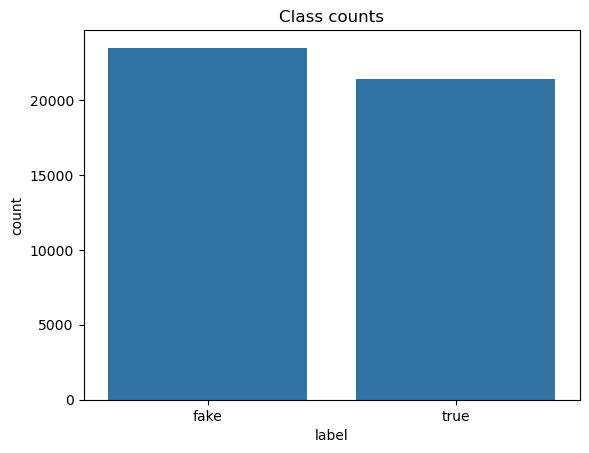

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.title("Class counts")
plt.show()


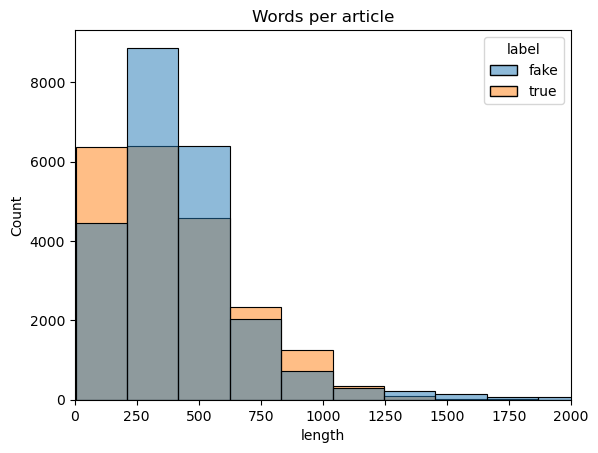

In [6]:
sns.histplot(data=df, x="length", hue="label", bins=40)
plt.xlim(0, 2000)
plt.title("Words per article")
plt.show()


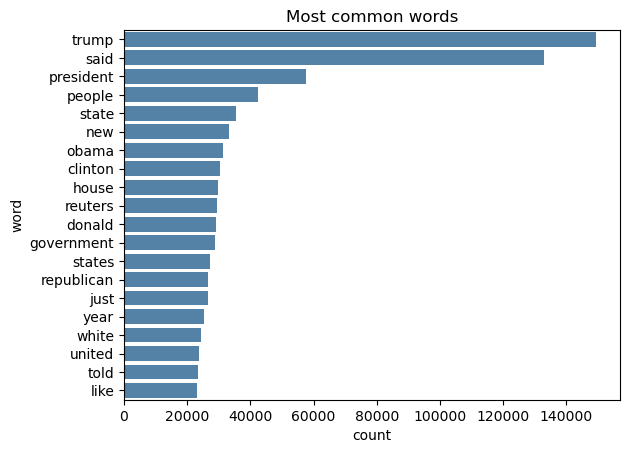

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

vect = CountVectorizer(stop_words="english", max_features=20)
word_counts = vect.fit_transform(df["text"])
top_words = pd.DataFrame({
    "word": vect.get_feature_names_out(),
    "count": word_counts.sum(axis=0).A1,
}).sort_values("count", ascending=False)

sns.barplot(data=top_words, x="count", y="word", color="steelblue")
plt.title("Most common words")
plt.show()


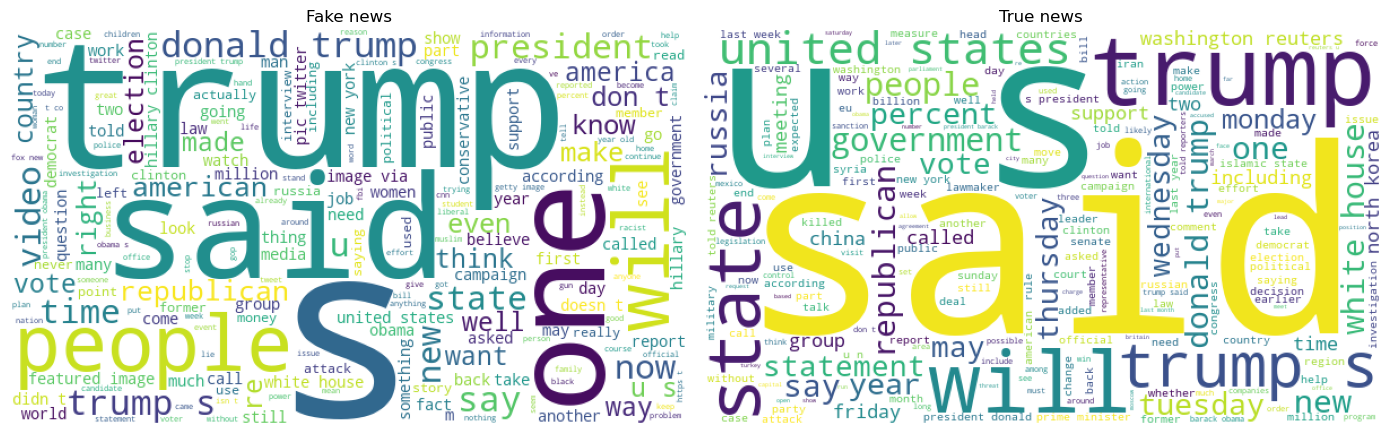

In [8]:
from wordcloud import WordCloud, STOPWORDS

fake_text = " ".join(df.loc[df["label"] == "fake", "text"].sample(2000, random_state=42).astype(str))
true_text = " ".join(df.loc[df["label"] == "true", "text"].sample(2000, random_state=42).astype(str))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(fake_text))
plt.title("Fake news")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(true_text))
plt.title("True news")
plt.axis("off")
plt.tight_layout()
plt.show()


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

x = df["text"]
y = df["label"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

lr = Pipeline([
    ("vect", TfidfVectorizer(stop_words="english", max_features=5000)),
    ("model", LogisticRegression(max_iter=1000)),
])
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)

print("Logistic Regression")
print(classification_report(y_test, lr_pred))


Logistic Regression
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99      4696
        true       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



In [10]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

tf.keras.utils.set_random_seed(42)

le = LabelEncoder()
y_tr = le.fit_transform(y_train)
y_te = le.transform(y_test)

vectorize = layers.TextVectorization(max_tokens=10000, output_sequence_length=250)
vectorize.adapt(x_train.to_numpy())

dl = tf.keras.Sequential([
    vectorize,
    layers.Embedding(10000, 64),
    layers.Conv1D(64, 5, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
dl.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
hist = dl.fit(
    x_train.to_numpy(), y_tr,
    validation_split=0.1,
    epochs=6,
    batch_size=128,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)

dl_pred = (dl.predict(x_test.to_numpy(), verbose=0).ravel() >= 0.5).astype(int)
print("1D CNN")
print(classification_report(y_te, dl_pred, target_names=le.classes_))


Epoch 1/6
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9541 - loss: 0.1339 - val_accuracy: 0.9944 - val_loss: 0.0189
Epoch 2/6
253/253 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9965 - loss: 0.0139 - val_accuracy: 0.9972 - val_loss: 0.0110
Epoch 3/6
253/253 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9988 - loss: 0.0058 - val_accuracy: 0.9972 - val_loss: 0.0119
Epoch 4/6
253/253 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9990 - loss: 0.0031 - val_accuracy: 0.9972 - val_loss: 0.0116
1D CNN
              precision    recall  f1-score   support

        fake       1.00      1.00      1.00      4696
        true       1.00      1.00      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



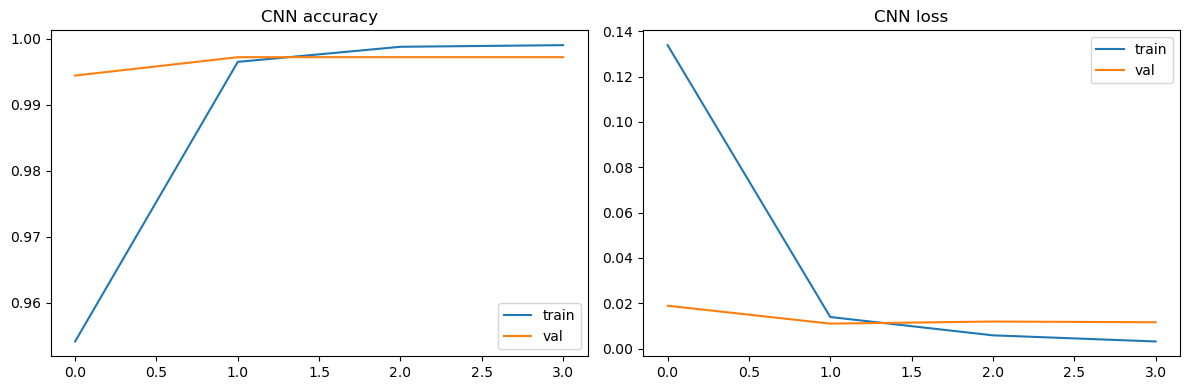

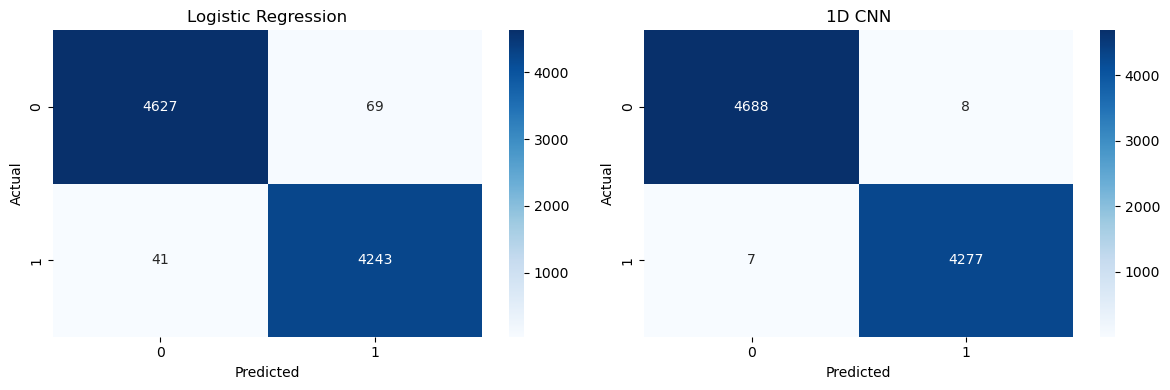

Logistic Regression accuracy 0.987750556792873 F1 0.9882528833831696
1D CNN               accuracy 0.9983296213808464 F1 0.9984027260142689


In [11]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("CNN accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("CNN loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(confusion_matrix(y_te, dl_pred), annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("1D CNN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

print("Logistic Regression accuracy", accuracy_score(y_test, lr_pred), "F1", f1_score(y_test, lr_pred, pos_label="fake"))
print("1D CNN               accuracy", accuracy_score(y_te, dl_pred), "F1", f1_score(y_te, dl_pred, pos_label=0))


In [12]:
samples = [
    "the president signed the budget after the vote in parliament",
    "scientists confirm aliens built the moon and the video is shocking",
]
print("Logistic Regression", lr.predict(samples))
print("1D CNN             ", le.inverse_transform((dl.predict(tf.constant(samples), verbose=0).ravel() >= 0.5).astype(int)))


Logistic Regression ['true' 'fake']
1D CNN              ['fake' 'fake']


In [13]:
dl.save("fake_news.keras")


# Conclusion

Fake and true articles were stacked and the title was joined to the body. Class counts, the top-word bar and the two word clouds sit before the models. Logistic Regression on 5000 TF-IDF words is the classical baseline. The 1D CNN is the deep model: it learns embeddings and looks at local word windows, which fits long news text better than a recurrent net. Fake-class F1 is the number to watch. The CNN is saved as fake_news.keras.
